# 02 · Funnel analysis and segment statistics

**Part A – Funnel** under multiple conditions: by device, channel, user type, loyalty status; promotion vs
normal days; before / after product changes; during incidents; plus a multivariable model.

**Part B – Segments**: users (age, gender, country, acquisition channel) and products (category, price tier),
cohort retention, and the loyalty programme with its selection bias.

**A note on significance with 24M rows.** At this sample size almost any difference has p < 0.001.
A small p-value therefore says "not noise", not "important". Every table reports an **effect size**
(relative difference, Cramér's V, Cohen's h, ε²) next to the p-value, and p-values across a family of
comparisons are Benjamini–Hochberg adjusted. P-values start to matter again in short windows
(incidents, promotions, experiments), where samples are small.

In [1]:
import sys, warnings
sys.path.insert(0, "../src"); sys.path.insert(0, "src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from shopstats import *
set_style()
pd.options.display.float_format = "{:,.4f}".format
pd.set_option("display.width", 250, "display.max_columns", 40, "display.max_colwidth", 70)
try:
    display
except NameError:
    display = print

cube = pd.read_parquet(OUT / "cube_day_channel_device.parquet")      # bots already excluded (notebook 01)
S = load_sessions(["user_id", "session_start", "channel", "device", "country", "is_new_user", "is_loyalty_member",
                   "pageviews", "duration_sec", "viewed_category", "viewed_product_id"] + FLAGS)
S = S[~bot_mask(S)].reset_index(drop=True)
O = load_orders()
I = pd.read_parquet(DATA / "order_items.parquet")
U = pd.read_parquet(DATA / "users.parquet")
P = pd.read_parquet(DATA / "products.parquet")
EV, PR = load_events()
print(f"{len(S):,} sessions after removing suspected bots")

23,827,675 sessions after removing suspected bots


# Part A · Funnel
## A1. Overall funnel

,stage,sessions,share of visits,step conversion,drop-off at step
0,Visit,23827675,1.0000,NaN,NaN
1,Product view,15496486,0.6504,0.6504,0.3496
2,Add to cart,3168774,0.1330,0.2045,0.7955
3,Checkout,1824052,0.0766,0.5756,0.4244
4,Payment,1380807,0.0579,0.7570,0.2430
5,Purchase,1179153,0.0495,0.8540,0.1460


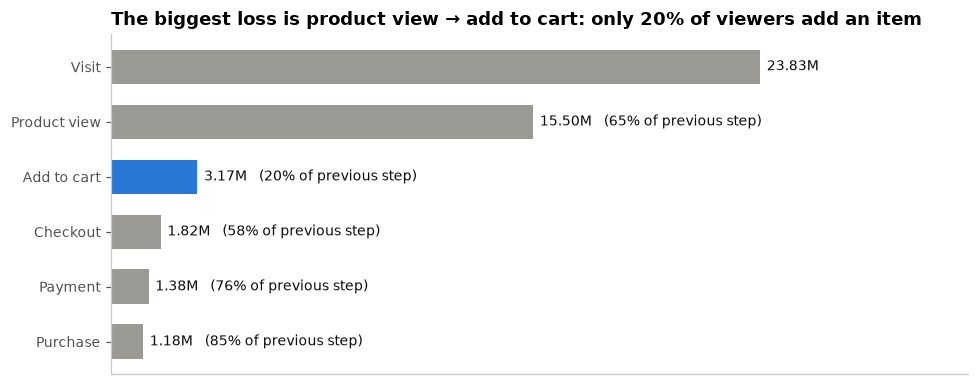

In [2]:
tot = cube[STAGES].sum()
ov = pd.DataFrame({"stage": STAGE_LABELS, "sessions": tot.values})
ov["share of visits"] = ov["sessions"] / ov["sessions"].iloc[0]
ov["step conversion"] = ov["sessions"] / ov["sessions"].shift(1)
ov["drop-off at step"] = 1 - ov["step conversion"]
display(ov)
ov.to_csv(OUT / "funnel_overall.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(ov["stage"][::-1], ov["sessions"][::-1], color=GREY, height=0.62)
ax.barh(["Add to cart"], ov.loc[2, "sessions"], color=BLUE, height=0.62)
for i, r in ov.iterrows():
    lab = f"{r['sessions']/1e6:.2f}M" + ("" if i == 0 else f"   ({r['step conversion']:.0%} of previous step)")
    ax.text(r["sessions"] + tot.iloc[0] * 0.01, len(ov) - 1 - i, lab, va="center", fontsize=9, color=INK)
ax.set_xlim(0, tot.iloc[0] * 1.32); ax.xaxis.set_visible(False); ax.grid(False)
ax.set_title(f"The biggest loss is product view → add to cart: only {ov.loc[2, 'step conversion']:.0%} of viewers add an item")
save(fig, "02_funnel_overall")

## A2. Funnel by segment
For each dimension: step-to-step conversion per segment, a chi-square test of homogeneity per step, and
Cramér's V as the effect size (0.01 ≈ negligible, 0.05 ≈ small, 0.15+ ≈ material for a binary outcome).

In [3]:
def funnel_by(dim, df=cube):
    g = funnel_rates(df.groupby(dim, observed=True)[STAGES].sum())
    tests = []
    for prev, cur, name in zip(STAGES[:-1], STAGES[1:], STEP_NAMES):
        chi2, p, dof, v = cramers_v(np.vstack([g[cur].values, (g[prev] - g[cur]).clip(lower=0).values]))
        spread = g[name].max() / g[name].min() - 1
        tests.append(dict(dimension=dim, step=name, chi2=chi2, dof=dof, p=p, cramers_v=v, best_vs_worst=spread))
    return g, pd.DataFrame(tests)

all_tests, funnels = [], {}
for dim in ["device", "channel", "is_new_user", "is_loyalty_member"]:
    g, t = funnel_by(dim)
    funnels[dim] = g
    all_tests.append(t)
    print(f"\n── funnel by {dim} ──")
    display(g[["sessions"] + STEP_NAMES + ["overall"]])
    out = g.reset_index().rename(columns={dim: "segment"}); out.insert(0, "dimension", dim)
    out.to_csv(OUT / f"funnel_by_{dim}.csv", index=False)
tests = pd.concat(all_tests, ignore_index=True)
tests["p_adj"] = bh(tests["p"])
tests["p"] = tests["p"].map(fmt_p); tests["p_adj"] = tests["p_adj"].map(fmt_p)
print("\nChi-square homogeneity tests per step (20 tests, BH-adjusted) with effect sizes")
display(tests)
tests.to_csv(OUT / "funnel_segment_tests.csv", index=False)


── funnel by device ──


,sessions,visit→view,view→cart,cart→checkout,checkout→payment,payment→purchase,overall
device,,,,,,,
desktop,8917093,0.7094,0.2293,0.6262,0.7999,0.8791,0.0716
mobile,13023094,0.6114,0.1858,0.5276,0.7091,0.8215,0.0349
tablet,1887488,0.6406,0.1981,0.5661,0.7452,0.8507,0.0456



── funnel by channel ──


,sessions,visit→view,view→cart,cart→checkout,checkout→payment,payment→purchase,overall
channel,,,,,,,
Organic Search,6862319,0.6396,0.1951,0.5765,0.7583,0.8545,0.0466
Paid Search,5085957,0.6620,0.1854,0.5752,0.7568,0.8544,0.0456
Direct,4196599,0.6735,0.2380,0.5755,0.7566,0.8528,0.0595
Social,3324336,0.5788,0.1338,0.5794,0.7570,0.8553,0.0291
Email,2782716,0.7057,0.2774,0.5736,0.7568,0.8536,0.0725
Affiliate,1575748,0.6514,0.2079,0.5745,0.7542,0.8538,0.0501



── funnel by is_new_user ──


,sessions,visit→view,view→cart,cart→checkout,checkout→payment,payment→purchase,overall
is_new_user,,,,,,,
False,20954702,0.6528,0.2132,0.5762,0.7571,0.8540,0.0519
True,2872973,0.6325,0.1385,0.5685,0.7558,0.8530,0.0321



── funnel by is_loyalty_member ──


,sessions,visit→view,view→cart,cart→checkout,checkout→payment,payment→purchase,overall
is_loyalty_member,,,,,,,
False,20634342,0.6502,0.1927,0.5683,0.7569,0.8540,0.0460
True,3193333,0.6517,0.2802,0.6080,0.7575,0.8538,0.0718



Chi-square homogeneity tests per step (20 tests, BH-adjusted) with effect sizes


,dimension,step,chi2,dof,p,cramers_v,best_vs_worst,p_adj
0,device,visit→view,"224,310.2012",2,<1e-300,0.0970,0.1603,<1e-300
1,device,view→cart,"41,312.5948",2,<1e-300,0.0516,0.2341,<1e-300
2,device,cart→checkout,"29,264.8283",2,<1e-300,0.0961,0.1870,<1e-300
3,device,checkout→payment,"18,897.8096",2,<1e-300,0.1018,0.1280,<1e-300
4,device,payment→purchase,"8,353.5527",2,<1e-300,0.0778,0.0701,<1e-300
5,channel,visit→view,"128,828.2453",5,<1e-300,0.0735,0.2193,<1e-300
6,channel,view→cart,"152,691.4275",5,<1e-300,0.0993,1.0725,<1e-300
7,channel,cart→checkout,28.6239,5,2.75e-05,0.0030,0.0101,3.93e-05
8,channel,checkout→payment,9.9855,5,0.0756,0.0023,0.0054,0.1009
9,channel,payment→purchase,6.3443,5,0.2741,0.0021,0.0030,0.3225


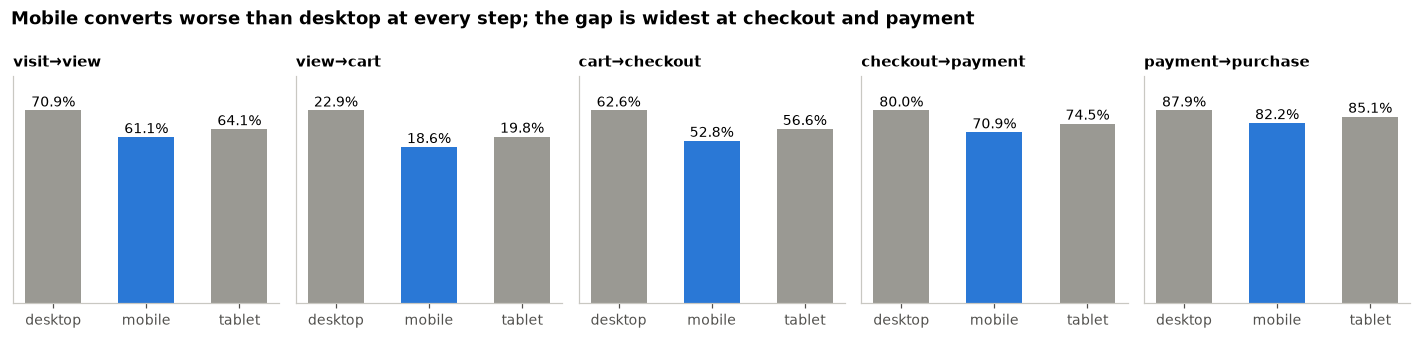

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(13, 3.1), sharey=False)
g = funnels["device"]
for ax, name in zip(axes, STEP_NAMES):
    n_prev = g[STAGES[STEP_NAMES.index(name)]]
    p, lo, hi = wilson(g[STAGES[STEP_NAMES.index(name) + 1]], n_prev)
    cols = [GREY, BLUE, GREY]
    ax.bar(g.index.astype(str), p, color=cols, width=0.6)
    for i, v in enumerate(p):
        ax.text(i, v + p.max() * 0.02, f"{v:.1%}", ha="center", fontsize=9)
    ax.set_ylim(0, p.max() * 1.18); ax.set_title(name, fontsize=10); ax.yaxis.set_visible(False); ax.grid(False)
fig.suptitle("Mobile converts worse than desktop at every step; the gap is widest at checkout and payment",
             x=0.01, ha="left", fontweight="bold")
save(fig, "02_funnel_by_device")

**What the segment funnels say**

* **Device** — mobile is ~55% of traffic but loses at every step; the gap compounds to roughly half of desktop's
  overall conversion. The late steps (checkout → payment → purchase) are where mobile is relatively weakest, which is what
  motivated the one-page checkout experiment (notebook 03).
* **Channel** — differences are concentrated in the *early* funnel (view, add-to-cart): Email and Direct bring
  high-intent visitors, Social brings browsers. Once a cart exists, channels behave almost identically
  (Cramér's V ≈ 0 on the last three steps): **channel changes who arrives, not how well checkout works**.
* **New vs returning** and **loyalty** — again an add-to-cart story. Late-funnel differences are small.
* All 20 tests are "significant"; the effect-size column is what separates the material ones from the trivia.

## A3. Funnel under changing conditions
Each comparison is a two-proportion z-test on the affected step, with the relative change and its 95% CI.
Where a control group exists we also report the **difference-in-differences** (ratio of ratios), which removes
whatever else changed between the two periods.

In [5]:
catcube = (S[S["viewed_product"]].groupby(["day", "viewed_category", "device"], observed=True)
           .agg(viewed_product=("purchased", "size"), **{f: (f, "sum") for f in FLAGS[1:]}).reset_index())
catcube.to_parquet(OUT / "cube_day_category_device.parquet", index=False)

def counts(df, a, b, **filt):
    m = df["day"].between(day_index(a), day_index(b))
    for k, v in filt.items():
        m &= df[k].isin(v if isinstance(v, (list, tuple)) else [v])
    return df.loc[m, [c for c in STAGES if c in df.columns]].sum()

def compare(label, step, base, test, df=cube, group="", **filt):
    prev, cur = STAGES[STEP_NAMES.index(step)], STAGES[STEP_NAMES.index(step) + 1]
    c0, c1 = counts(df, *base, **filt), counts(df, *test, **filt)
    r = two_prop(c0[cur], c0[prev], c1[cur], c1[prev])
    return dict(condition=label, group=group, step=step, n_base=int(c0[prev]), n_test=int(c1[prev]), base=r["p1"], test=r["p2"],
                rel_change=r["lift"], lo=r["lift_lo"], hi=r["lift_hi"], z=r["z"], p=r["p"], cohen_h=r["h"],
                _k=(c0[cur], c0[prev], c1[cur], c1[prev]))

def did(row_t, row_c):
    """ratio of ratios (treated change / control change) with a log-scale CI"""
    k0, n0, k1, n1 = row_t["_k"]; c0, m0, c1, m1 = row_c["_k"]
    lr = np.log((k1 / n1) / (k0 / n0)) - np.log((c1 / m1) / (c0 / m0))
    se = np.sqrt(sum((1 - k / n) / k for k, n in [(k0, n0), (k1, n1), (c0, m0), (c1, m1)]))
    return np.exp(lr) - 1, np.exp(lr - 1.96 * se) - 1, np.exp(lr + 1.96 * se) - 1, 2 * stats.norm.sf(abs(lr / se))

rows, dids = [], []
# 1) Black Friday week vs the four weeks before the pre-promo lull
for yr, bf in (("2024", ("2024-11-29", "2024-12-02")), ("2025", ("2025-11-28", "2025-12-01"))):
    base = ("2024-11-01", "2024-11-21") if yr == "2024" else ("2025-10-27", "2025-11-20")
    for step in ["view→cart", "cart→checkout"]:
        rows.append(compare(f"Black Friday {yr} vs prior weeks", step, base, bf, group="all"))
# 2) Mobile checkout bug (10–13 Jun 2025) vs prior 2 weeks, desktop as control
for step in ["payment→purchase"]:
    t = compare("Mobile checkout bug 10–13 Jun 2025", step, ("2025-05-27", "2025-06-09"), ("2025-06-10", "2025-06-13"), group="mobile", device="mobile")
    c = compare("Mobile checkout bug 10–13 Jun 2025", step, ("2025-05-27", "2025-06-09"), ("2025-06-10", "2025-06-13"), group="desktop (control)", device="desktop")
    rows += [t, c]; dids.append(("Mobile checkout bug", step, *did(t, c)))
# 3) One-page checkout rollout: 8 weeks before the A/B test vs 8 weeks after 100% rollout
for step in ["checkout→payment", "payment→purchase"]:
    t = compare("One-page checkout rollout (8 wks before test vs 8 wks after)", step, ("2026-01-05", "2026-03-01"), ("2026-05-04", "2026-06-28"), group="mobile", device="mobile")
    c = compare("One-page checkout rollout (8 wks before test vs 8 wks after)", step, ("2026-01-05", "2026-03-01"), ("2026-05-04", "2026-06-28"), group="desktop (control)", device="desktop")
    rows += [t, c]; dids.append(("One-page checkout rollout", step, *did(t, c)))
# 4) Electronics price increase (+8% on 1 Sep 2025): 8 weeks either side, other categories as control
other = [c for c in catcube["viewed_category"].cat.categories if c != "Electronics"]
t = compare("Electronics +8% price (8 wks before vs after 1 Sep 2025)", "view→cart", ("2025-07-07", "2025-08-17"), ("2025-09-01", "2025-10-04"), df=catcube, group="Electronics", viewed_category="Electronics")
c = compare("Electronics +8% price (8 wks before vs after 1 Sep 2025)", "view→cart", ("2025-07-07", "2025-08-17"), ("2025-09-01", "2025-10-04"), df=catcube, group="other categories (control)", viewed_category=other)
rows += [t, c]; dids.append(("Electronics price increase", "view→cart", *did(t, c)))
# 5) Competitor campaign (5–25 May 2025), electronics vs others, vs the 3 weeks before
t = compare("Competitor campaign 5–25 May 2025 vs prior 3 weeks", "view→cart", ("2025-04-14", "2025-05-04"), ("2025-05-05", "2025-05-25"), df=catcube, group="Electronics", viewed_category="Electronics")
c = compare("Competitor campaign 5–25 May 2025 vs prior 3 weeks", "view→cart", ("2025-04-14", "2025-05-04"), ("2025-05-05", "2025-05-25"), df=catcube, group="other categories (control)", viewed_category=other)
rows += [t, c]; dids.append(("Competitor campaign", "view→cart", *did(t, c)))
# 6) Heatwave (23 Jun – 2 Jul 2026): Home & Garden vs others
oth = [c for c in catcube["viewed_category"].cat.categories if c != "Home & Garden"]
t = compare("Heatwave 23 Jun–2 Jul 2026 vs prior 3 weeks", "view→cart", ("2026-06-01", "2026-06-16"), ("2026-06-23", "2026-07-02"), df=catcube, group="Home & Garden", viewed_category="Home & Garden")
c = compare("Heatwave 23 Jun–2 Jul 2026 vs prior 3 weeks", "view→cart", ("2026-06-01", "2026-06-16"), ("2026-06-23", "2026-07-02"), df=catcube, group="other categories (control)", viewed_category=oth)
rows += [t, c]; dids.append(("Heatwave", "view→cart", *did(t, c)))
# 7) Viral social spike (9–11 Aug 2025): Social channel vs prior 2 weeks
for step in ["visit→view", "view→cart"]:
    rows.append(compare("Viral social spike 9–11 Aug 2025 vs prior 2 weeks", step, ("2025-07-26", "2025-08-08"), ("2025-08-09", "2025-08-11"), group="Social", channel="Social"))
# 8) Weekend vs weekday (whole period)
wk = cube.assign(weekend=DAYS.dayofweek.values[cube["day"]] >= 5).groupby("weekend")[STAGES].sum()
for step in STEP_NAMES:
    prev, cur = STAGES[STEP_NAMES.index(step)], STAGES[STEP_NAMES.index(step) + 1]
    r = two_prop(wk.loc[False, cur], wk.loc[False, prev], wk.loc[True, cur], wk.loc[True, prev])
    rows.append(dict(condition="Weekend vs weekday (24 months)", group="all", step=step, n_base=int(wk.loc[False, prev]), n_test=int(wk.loc[True, prev]),
                     base=r["p1"], test=r["p2"], rel_change=r["lift"], lo=r["lift_lo"], hi=r["lift_hi"], z=r["z"], p=r["p"], cohen_h=r["h"]))

cond = pd.DataFrame(rows).drop(columns="_k")
cond["p_adj"] = bh(cond["p"]); cond["sig"] = cond["p_adj"].map(stars)
cond.to_csv(OUT / "funnel_conditions.csv", index=False)
fmt = cond.copy()
for c in ["base", "test"]: fmt[c] = fmt[c].map("{:.2%}".format)
fmt["rel_change (95% CI)"] = cond.apply(lambda r: f"{r.rel_change:+.1%} [{r.lo:+.1%}, {r.hi:+.1%}]", axis=1)
fmt["p_adj"] = cond["p_adj"].map(fmt_p)
display(fmt[["condition", "group", "step", "n_test", "base", "test", "rel_change (95% CI)", "cohen_h", "p_adj", "sig"]])

dd = pd.DataFrame(dids, columns=["condition", "step", "did_effect", "lo", "hi", "p"])
dd.to_csv(OUT / "funnel_did.csv", index=False)
print("\nDifference-in-differences (treated group's change relative to its control group's change)")
display(dd.assign(**{"effect (95% CI)": dd.apply(lambda r: f"{r.did_effect:+.1%} [{r.lo:+.1%}, {r.hi:+.1%}]", axis=1), "p": dd["p"].map(fmt_p)})[["condition", "step", "effect (95% CI)", "p"]])

,condition,group,step,n_test,base,test,rel_change (95% CI),cohen_h,p_adj,sig
0,Black Friday 2024 vs prior weeks,all,view→cart,176856,19.90%,26.62%,"+33.8% [+32.5%, +35.2%]",0.1596,<1e-300,***
1,Black Friday 2024 vs prior weeks,all,cart→checkout,47087,56.97%,60.42%,"+6.1% [+5.1%, +7.1%]",0.0702,4.87e-33,***
2,Black Friday 2025 vs prior weeks,all,view→cart,209034,20.67%,27.43%,"+32.7% [+31.5%, +33.8%]",0.1584,<1e-300,***
3,Black Friday 2025 vs prior weeks,all,cart→checkout,57342,57.65%,60.79%,"+5.5% [+4.6%, +6.3%]",0.0639,2.86e-35,***
4,Mobile checkout bug 10–13 Jun 2025,mobile,payment→purchase,2441,82.38%,47.07%,"-42.9% [-45.3%, -40.3%]",-0.7630,6.79e-277,***
5,Mobile checkout bug 10–13 Jun 2025,desktop (control),payment→purchase,3315,88.37%,88.57%,"+0.2% [-1.1%, +1.6%]",0.0063,0.7476,ns
6,One-page checkout rollout (8 wks before test vs 8 wks after),mobile,checkout→payment,66205,70.10%,72.94%,"+4.1% [+3.3%, +4.8%]",0.0630,2.42e-27,***
7,One-page checkout rollout (8 wks before test vs 8 wks after),desktop (control),checkout→payment,71417,80.00%,79.78%,"-0.3% [-0.8%, +0.3%]",-0.0055,0.4054,ns
8,One-page checkout rollout (8 wks before test vs 8 wks after),mobile,payment→purchase,48291,82.09%,82.89%,"+1.0% [+0.4%, +1.6%]",0.0211,0.0034,**
9,One-page checkout rollout (8 wks before test vs 8 wks after),desktop (control),payment→purchase,56980,87.81%,87.63%,"-0.2% [-0.6%, +0.2%]",-0.0054,0.4173,ns



Difference-in-differences (treated group's change relative to its control group's change)


,condition,step,effect (95% CI),p
0,Mobile checkout bug,payment→purchase,"-43.0% [-45.5%, -40.3%]",1.48e-130
1,One-page checkout rollout,checkout→payment,"+4.3% [+3.4%, +5.3%]",1.64e-20
2,One-page checkout rollout,payment→purchase,"+1.2% [+0.4%, +2.0%]",0.0026
3,Electronics price increase,view→cart,"-6.0% [-7.6%, -4.3%]",4.02e-12
4,Competitor campaign,view→cart,"-19.1% [-21.1%, -17.0%]",2.19e-61
5,Heatwave,view→cart,"+18.3% [+15.3%, +21.2%]",2.35e-39


**Reading the conditions table**

* **Black Friday** lifts add-to-cart by a third and also improves cart → checkout; the effect replicates in both years.
* **Mobile checkout bug**: payment → purchase on mobile falls by 43% for four days; desktop does not move, so the
  difference-in-differences attributes the whole drop to the bug rather than to the calendar.
* **One-page checkout rollout**: mobile checkout → payment and payment → purchase both improve after rollout, desktop is flat.
  The DiD estimate is the cleanest *observational* confirmation of the A/B result.
* **Electronics price increase**: view → cart falls for Electronics relative to other categories, a modest but significant
  and *permanent* shift (the trade-off against the higher price is priced out in notebook 03).
* **Competitor campaign** and **heatwave** are external shocks visible only in the affected category — which is why the
  control-category comparison is needed to see them clearly.
* **Viral spike**: the Social funnel deteriorates at both early steps; the extra visitors were curious, not shopping.
* **Weekend vs weekday**: statistically significant on 24M sessions, but Cohen's h is ~0.00–0.01. This is the textbook
  case of a real but practically irrelevant difference.

## A4. Multivariable view: which factors matter once the others are held fixed?
Segments overlap (Email visitors are mostly returning desktop users, etc.). A binomial GLM on the aggregated cells gives
adjusted odds ratios for purchase per session. Standard errors are scaled by the Pearson dispersion to
allow for overdispersion between cells.

Pearson dispersion = 3.9 (1 would mean pure binomial noise); standard errors are inflated by its square root


,odds ratio,lo,hi,p,vs
device: mobile,0.4684,0.4648,0.4720,0.0000,desktop
device: tablet,0.6178,0.6090,0.6267,0.0000,desktop
channel: Affiliate,1.0899,1.0729,1.1072,0.0000,Organic Search
channel: Direct,1.2681,1.2547,1.2816,0.0000,Organic Search
channel: Email,1.5455,1.5279,1.5632,0.0000,Organic Search
channel: Paid Search,0.9971,0.9864,1.0079,0.5969,Organic Search
channel: Social,0.6261,0.6171,0.6352,0.0000,Organic Search
new user,0.7679,0.7574,0.7787,0.0000,returning
loyalty member,1.5477,1.5332,1.5623,0.0000,non-member


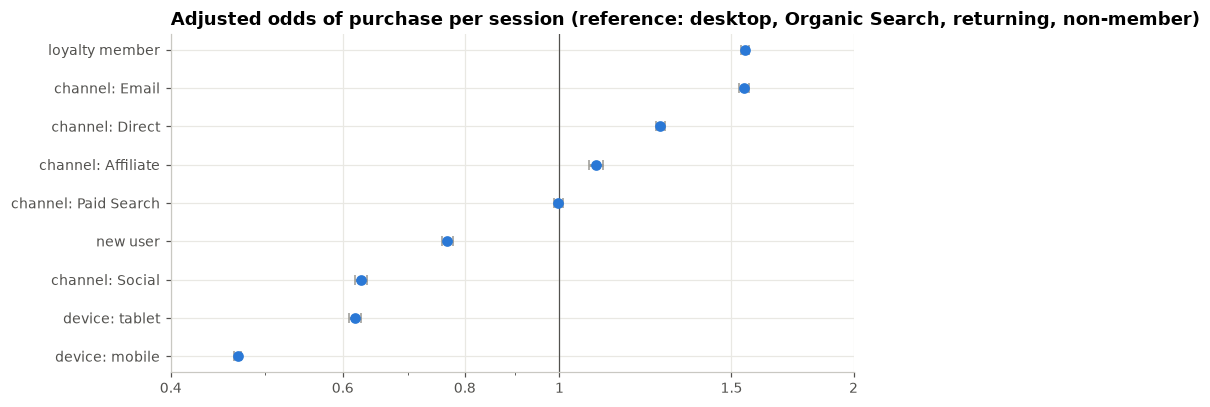

In [6]:
cells = cube.groupby(["device", "channel", "is_new_user", "is_loyalty_member"], observed=True)[["sessions", "purchased"]].sum().reset_index()
Xg = pd.get_dummies(cells[["device", "channel"]].astype(str), drop_first=False, dtype=float)
Xg = Xg.drop(columns=["device_desktop", "channel_Organic Search"])
Xg["new user"] = cells["is_new_user"].astype(float); Xg["loyalty member"] = cells["is_loyalty_member"].astype(float)
Xg = sm.add_constant(Xg)
def binom_glm(k, n, X):
    """Binomial GLM on grouped counts; standard errors inflated by the Pearson dispersion."""
    k, n = np.asarray(k, float), np.asarray(n, float)
    fit = sm.GLM(k / n, X, family=sm.families.Binomial(), var_weights=n).fit()
    mu = fit.fittedvalues
    disp = max(np.sum(n * (k / n - mu) ** 2 / (mu * (1 - mu))) / max(fit.df_resid, 1), 1.0)
    se = fit.bse * np.sqrt(disp)
    return pd.DataFrame({"odds ratio": np.exp(fit.params), "lo": np.exp(fit.params - 1.96 * se), "hi": np.exp(fit.params + 1.96 * se),
                         "p": 2 * stats.norm.sf(np.abs(fit.params / se))}), disp

ors, disp = binom_glm(cells["purchased"], cells["sessions"], Xg)
ors = ors.drop("const")
ors.index = [i.replace("device_", "device: ").replace("channel_", "channel: ") for i in ors.index]
ors["vs"] = ["desktop"] * 2 + ["Organic Search"] * 5 + ["returning", "non-member"]
print(f"Pearson dispersion = {disp:.1f} (1 would mean pure binomial noise); standard errors are inflated by its square root")
display(ors)
ors.to_csv(OUT / "funnel_glm_odds_ratios.csv")

fig, ax = plt.subplots(figsize=(8, 3.8))
o = ors.sort_values("odds ratio")
ax.errorbar(o["odds ratio"], range(len(o)), xerr=[o["odds ratio"] - o["lo"], o["hi"] - o["odds ratio"]], fmt="o", color=BLUE, ecolor=GREY, capsize=3)
ax.axvline(1, color=INK2, lw=0.8)
ax.set_yticks(range(len(o))); ax.set_yticklabels(o.index); ax.set_xscale("log")
ax.set_xticks([0.4, 0.6, 0.8, 1, 1.5, 2]); ax.set_xticklabels(["0.4", "0.6", "0.8", "1", "1.5", "2"])
ax.set_title("Adjusted odds of purchase per session (reference: desktop, Organic Search, returning, non-member)")
save(fig, "02_odds_ratios")

# Part B · Segment statistics
## B1. User segments
Per-user metrics over the full 24 months (users with at least one non-bot session). For each dimension:
buyer rate with Wilson 95% CI, chi-square + Cramér's V on buyer rate, and Kruskal–Wallis + ε² on revenue among buyers
(revenue is heavily right-skewed, so a rank test is safer than ANOVA).

In [7]:
nU = len(U)
U["sessions"] = np.bincount(S["user_id"].values, minlength=nU + 1)[1:]
ok = O["status"].ne("cancelled").values
U["orders"] = np.bincount(O["user_id"].values[ok], minlength=nU + 1)[1:]
U["revenue"] = np.bincount(O["user_id"].values[ok], O["revenue"].values[ok] - O["refund_amount"].values[ok], minlength=nU + 1)[1:]
U["buyer"] = U["orders"] > 0
U["member"] = np.where(U["loyalty_join_date"].notna(), "Loyalty member", "Non-member")
UA = U[U["sessions"] > 0]
print(f"{len(UA):,} active users, {UA['buyer'].sum():,} buyers ({UA['buyer'].mean():.1%}); "
      f"net revenue per user ${UA['revenue'].mean():.2f}, per buyer ${UA.loc[UA['buyer'], 'revenue'].mean():.2f}")

seg_rows, seg_tests = [], []
for dim in ["age_group", "gender", "country", "acquisition_channel", "preferred_device", "member"]:
    g = UA.groupby(dim, observed=True).agg(users=("user_id", "size"), buyers=("buyer", "sum"), sessions=("sessions", "sum"),
                                           orders=("orders", "sum"), revenue=("revenue", "sum"),
                                           rev_sd=("revenue", "std"))
    g["buyer_rate"], g["buyer_lo"], g["buyer_hi"] = wilson(g["buyers"], g["users"])
    g["sessions_per_user"] = g["sessions"] / g["users"]
    g["orders_per_buyer"] = g["orders"] / g["buyers"]
    g["aov"] = g["revenue"] / g["orders"]
    g["rev_per_user"] = g["revenue"] / g["users"]
    g["rev_ci"] = 1.96 * g["rev_sd"] / np.sqrt(g["users"])
    chi2, p, dof, v = cramers_v(np.vstack([g["buyers"], g["users"] - g["buyers"]]))
    groups = [UA.loc[UA[dim].eq(k) & UA["buyer"], "revenue"].values for k in g.index]
    H, pk = stats.kruskal(*groups)
    n_b = sum(len(x) for x in groups)
    seg_tests.append(dict(dimension=dim, chi2_buyer_rate=chi2, p_buyer_rate=p, cramers_v=v,
                          kw_H_revenue=H, p_revenue=pk, epsilon2=(H - len(groups) + 1) / (n_b - len(groups))))
    print(f"\n── users by {dim} ──")
    display(g[["users", "buyer_rate", "buyer_lo", "buyer_hi", "sessions_per_user", "orders_per_buyer", "aov", "rev_per_user", "rev_ci"]])
    out = g.reset_index().rename(columns={dim: "segment"}); out.insert(0, "dimension", dim); seg_rows.append(out)
segs = pd.concat(seg_rows, ignore_index=True)
segs.to_csv(OUT / "segments_users.csv", index=False)
st = pd.DataFrame(seg_tests)
st["p_buyer_rate_adj"] = bh(st["p_buyer_rate"]); st["p_revenue_adj"] = bh(st["p_revenue"])
st.to_csv(OUT / "segments_users_tests.csv", index=False)
print("\nTests across segments (BH-adjusted within each family of 6)")
display(st.assign(p_buyer_rate_adj=st["p_buyer_rate_adj"].map(fmt_p), p_revenue_adj=st["p_revenue_adj"].map(fmt_p))
        [["dimension", "cramers_v", "p_buyer_rate_adj", "epsilon2", "p_revenue_adj"]])

3,282,150 active users, 757,024 buyers (23.1%); net revenue per user $36.53, per buyer $158.40



── users by age_group ──


,users,buyer_rate,buyer_lo,buyer_hi,sessions_per_user,orders_per_buyer,aov,rev_per_user,rev_ci
age_group,,,,,,,,,
18-24,524147,0.2000,0.1989,0.2011,7.2754,1.4505,103.1499,29.9279,0.3120
25-34,985771,0.2234,0.2226,0.2242,7.2533,1.5019,104.0155,34.9012,0.2514
35-44,787737,0.2380,0.2371,0.2389,7.2446,1.5405,104.2095,38.2064,0.2977
45-54,524242,0.2483,0.2472,0.2495,7.2703,1.5641,103.7916,40.3167,0.3784
55+,460253,0.2483,0.2471,0.2496,7.2700,1.5656,103.8989,40.3899,0.4031



── users by gender ──


,users,buyer_rate,buyer_lo,buyer_hi,sessions_per_user,orders_per_buyer,aov,rev_per_user,rev_ci
gender,,,,,,,,,
F,1705959,0.2336,0.2330,0.2342,7.2580,1.5326,93.7259,33.5556,0.1801
M,1444238,0.2271,0.2265,0.2278,7.2614,1.5154,116.5252,40.1082,0.2341
Unspecified,131953,0.2309,0.2286,0.2331,7.2648,1.5209,102.3691,35.9436,0.6885



── users by country ──


... (5 outputs left out)


── users by member ──


,users,buyer_rate,buyer_lo,buyer_hi,sessions_per_user,orders_per_buyer,aov,rev_per_user,rev_ci
member,,,,,,,,,
Loyalty member,554352,0.3345,0.3332,0.3357,9.1346,1.7608,104.4319,61.5064,0.4729
Non-member,2727798,0.2095,0.2091,0.2100,6.8788,1.4480,103.6796,31.4601,0.1404



Tests across segments (BH-adjusted within each family of 6)


,dimension,cramers_v,p_buyer_rate_adj,epsilon2,p_revenue_adj
0,age_group,0.0392,<1e-300,0.0003,7.51e-49
1,gender,0.0075,7.50e-41,0.0042,<1e-300
2,country,0.0078,7.50e-41,0.0001,5.09e-08
3,acquisition_channel,0.0258,<1e-300,0.0000,9.56e-06
4,preferred_device,0.1227,<1e-300,0.0035,<1e-300
5,member,0.1111,<1e-300,0.0037,<1e-300


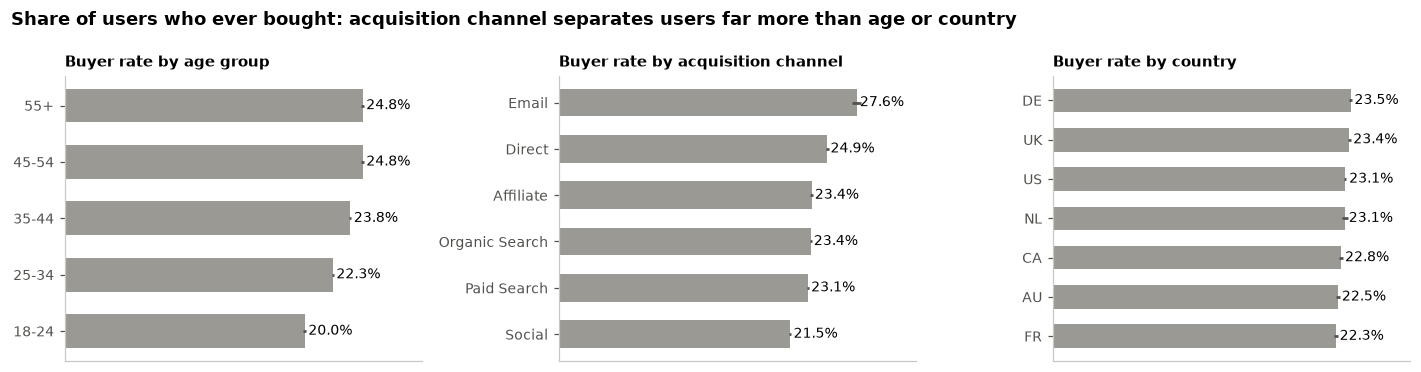

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, dim, title in zip(axes, ["age_group", "acquisition_channel", "country"], ["age group", "acquisition channel", "country"]):
    g = segs[segs["dimension"].eq(dim)].sort_values("buyer_rate") if dim != "age_group" else segs[segs["dimension"].eq(dim)]
    ax.barh(g["segment"].astype(str), g["buyer_rate"], color=GREY, height=0.6,
            xerr=[g["buyer_rate"] - g["buyer_lo"], g["buyer_hi"] - g["buyer_rate"]], ecolor=INK2)
    for i, v in enumerate(g["buyer_rate"]):
        ax.text(v + 0.003, i, f"{v:.1%}", va="center", fontsize=9)
    ax.set_xlim(0, g["buyer_rate"].max() * 1.2); ax.set_title(f"Buyer rate by {title}", fontsize=10); ax.xaxis.set_visible(False); ax.grid(False)
fig.suptitle("Share of users who ever bought: acquisition channel separates users far more than age or country",
             x=0.01, ha="left", fontweight="bold")
save(fig, "02_user_segments")

**User-segment findings**

* **Preferred device** is the strongest split (Cramér's V ≈ 0.12): desktop-first users are ~60% more likely to ever buy
  than mobile-first users and are worth almost twice as much per head.
* **Age**: buyer rate rises from 18–24 to 45–54. Statistically unambiguous, small in size (V ≈ 0.04).
* **Acquisition channel**: Social-acquired users are the least likely to become buyers, Direct the most; a small effect.
* **Country** and **gender**: p-values are tiny, effect sizes are negligible (V < 0.01). Do not build a strategy on them.
* **Revenue among buyers** barely differs between segments (ε² ≈ 0): segments differ in *whether* people buy, much less in
  *how much* they spend once they do.
* **Loyalty members** look far better than non-members, but that comparison is confounded — see B5.

## B2. Product segments

,lines,revenue,revenue_share,avg_unit_price,margin_pct,avg_discount,return_rate,ret_lo,ret_hi
category,,,,,,,,,
Electronics,299677,"63,511,001.6200",0.4820,184.2212,0.2489,0.0149,0.0711,0.0702,0.0720
Fashion,437037,"20,853,779.8900",0.1583,41.5053,0.5065,0.0268,0.1955,0.1943,0.1967
Home & Garden,263883,"19,248,850.8800",0.1461,63.3672,0.4092,0.0141,0.0812,0.0802,0.0823
Beauty,223231,"7,765,888.7000",0.0589,30.0889,0.5847,0.0169,0.0395,0.0387,0.0403
Sports & Outdoors,189053,"11,542,247.6000",0.0876,53.0556,0.3815,0.0097,0.0901,0.0888,0.0914
Toys & Games,145229,"4,071,860.2800",0.0309,24.3646,0.3544,0.0192,0.0515,0.0503,0.0526
Books & Media,164440,"3,049,471.7600",0.0231,16.1152,0.2985,0.0144,0.0198,0.0191,0.0205
Pet Supplies,65171,"1,719,317.1900",0.0130,22.9515,0.3527,0.0086,0.0304,0.0291,0.0317


return rate differs by category: chi2=80,416, dof=7, p=<1e-300, Cramér's V=0.212 (a material effect)
revenue concentration: top 10% of products = 64.1% of revenue, top 20% = 77.1%; Gini = 0.73


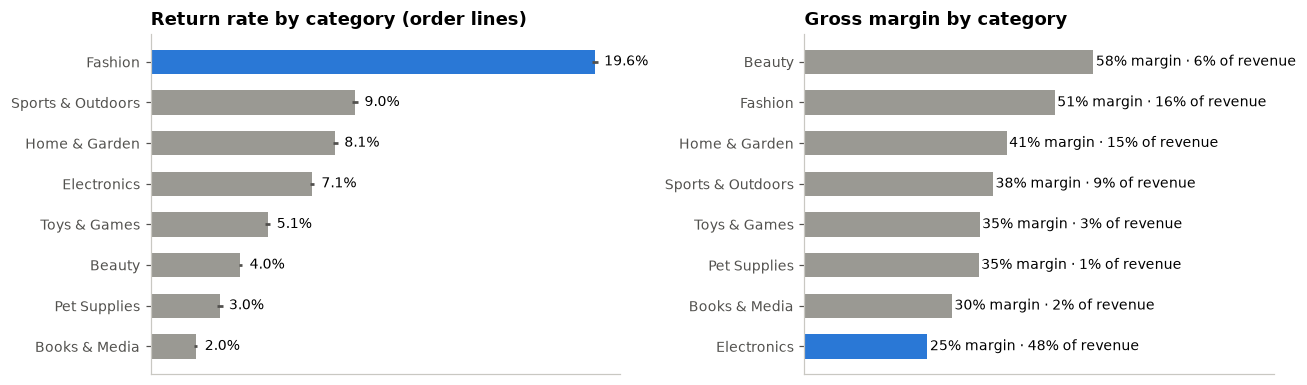

In [9]:
I["day"] = O["day"].values[I["order_id"].values - 1]
I["cancelled"] = O["status"].eq("cancelled").values[I["order_id"].values - 1]
I["line_rev"] = I["unit_price_paid"] * I["quantity"]
I["line_profit"] = (I["unit_price_paid"] - I["unit_cost"]) * I["quantity"]
I["line_list"] = I["list_price"] * I["quantity"]
J = I[~I["cancelled"]]
cat = J.groupby("category", observed=True).agg(lines=("order_id", "size"), units=("quantity", "sum"), revenue=("line_rev", "sum"),
                                               profit=("line_profit", "sum"), list_value=("line_list", "sum"), returned=("returned", "sum"))
cat["revenue_share"] = cat["revenue"] / cat["revenue"].sum()
cat["margin_pct"] = cat["profit"] / cat["revenue"]
cat["avg_discount"] = 1 - cat["revenue"] / cat["list_value"]
cat["avg_unit_price"] = cat["revenue"] / cat["units"]
cat["return_rate"], cat["ret_lo"], cat["ret_hi"] = wilson(cat["returned"], cat["lines"])
chi2, p, dof, v = cramers_v(np.vstack([cat["returned"], cat["lines"] - cat["returned"]]))
display(cat[["lines", "revenue", "revenue_share", "avg_unit_price", "margin_pct", "avg_discount", "return_rate", "ret_lo", "ret_hi"]])
print(f"return rate differs by category: chi2={chi2:,.0f}, dof={dof}, p={fmt_p(p)}, Cramér's V={v:.3f} (a material effect)")
cat.reset_index().to_csv(OUT / "segments_category.csv", index=False)

prod = J.groupby("product_id").agg(revenue=("line_rev", "sum"), units=("quantity", "sum")).sort_values("revenue", ascending=False)
share = prod["revenue"].cumsum() / prod["revenue"].sum()
x = np.sort(prod["revenue"].values); n = len(x)
gini = (2 * np.sum((np.arange(1, n + 1)) * x) / (n * x.sum())) - (n + 1) / n
print(f"revenue concentration: top 10% of products = {share.iloc[int(n * 0.1) - 1]:.1%} of revenue, "
      f"top 20% = {share.iloc[int(n * 0.2) - 1]:.1%}; Gini = {gini:.2f}")

mon = J.assign(month=DAYS[J["day"].values].to_period("M").astype(str)).groupby(["month", "category"], observed=True)["line_rev"].sum().unstack()
mon.to_csv(OUT / "monthly_revenue_by_category.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
c2 = cat.sort_values("return_rate")
axes[0].barh(c2.index.astype(str), c2["return_rate"], color=[BLUE if i == "Fashion" else GREY for i in c2.index], height=0.6,
             xerr=[c2["return_rate"] - c2["ret_lo"], c2["ret_hi"] - c2["return_rate"]], ecolor=INK2)
for i, v_ in enumerate(c2["return_rate"]):
    axes[0].text(v_ + 0.004, i, f"{v_:.1%}", va="center", fontsize=9)
axes[0].set_title("Return rate by category (order lines)"); axes[0].xaxis.set_visible(False); axes[0].grid(False)
c3 = cat.sort_values("margin_pct")
axes[1].barh(c3.index.astype(str), c3["margin_pct"], color=[BLUE if i == "Electronics" else GREY for i in c3.index], height=0.6)
for i, (m_, s_) in enumerate(zip(c3["margin_pct"], c3["revenue_share"])):
    axes[1].text(m_ + 0.005, i, f"{m_:.0%} margin · {s_:.0%} of revenue", va="center", fontsize=9)
axes[1].set_xlim(0, 0.95); axes[1].set_title("Gross margin by category"); axes[1].xaxis.set_visible(False); axes[1].grid(False)
save(fig, "02_category_segments")

* **Electronics** is the largest revenue line with the thinnest margin; **Fashion** earns more than twice the margin
  but one line in five comes back. Net of returns the two categories are closer than the revenue ranking suggests.
* Revenue is concentrated: the top tenth of products carries almost two-thirds of revenue, so SKU-level incidents
  (see the defective-batch detection in notebook 04) can be commercially meaningful.

## B3. Price tier × macro slowdown (an external factor that hits segments unequally)
Products are split into price quartiles *within their category*. We compare view → cart conversion during the macro
slowdown (20 Jan – 10 Apr 2026) with the same dates a year earlier, per tier. The test of interest is the
**interaction**: did premium items lose more than budget items?

In [10]:
P["tier"] = P.groupby("category", observed=True)["base_price"].transform(lambda s: pd.qcut(s, 4, labels=["Q1 budget", "Q2", "Q3", "Q4 premium"]).astype(str))
tier_of = np.array([""] + P["tier"].tolist(), dtype=object)
V = S.loc[S["viewed_product"], ["day", "viewed_product_id", "added_to_cart"]]
V = V.assign(tier=tier_of[V["viewed_product_id"].astype("int64").values])
per = np.where(V["day"].between(day_index("2026-01-20"), day_index("2026-04-10")), "2026 (slowdown)",
               np.where(V["day"].between(day_index("2025-01-20"), day_index("2025-04-10")), "2025 (baseline)", ""))
V = V.assign(period=per)[per != ""]
tp = V.groupby(["tier", "period"]).agg(views=("added_to_cart", "size"), carts=("added_to_cart", "sum")).unstack()
res = []
for t_ in tp.index:
    r = two_prop(tp.loc[t_, ("carts", "2025 (baseline)")], tp.loc[t_, ("views", "2025 (baseline)")],
                 tp.loc[t_, ("carts", "2026 (slowdown)")], tp.loc[t_, ("views", "2026 (slowdown)")])
    res.append(dict(tier=t_, cart_rate_2025=r["p1"], cart_rate_2026=r["p2"], rel_change=r["lift"], lo=r["lift_lo"], hi=r["lift_hi"], p=r["p"]))
tier = pd.DataFrame(res)
display(tier)
tier.to_csv(OUT / "segments_price_tier_macro.csv", index=False)
g = V.groupby(["tier", "period"]).agg(n=("added_to_cart", "size"), k=("added_to_cart", "sum")).reset_index()
Xi = pd.DataFrame({"const": 1.0, "slowdown": (g["period"] == "2026 (slowdown)").astype(float)})
for t_ in ["Q2", "Q3", "Q4 premium"]:
    Xi[t_] = (g["tier"] == t_).astype(float); Xi[f"{t_} × slowdown"] = Xi[t_] * Xi["slowdown"]
gi, _ = binom_glm(g["k"], g["n"], Xi)
print("interaction terms (odds ratio of the change relative to the budget tier's change):")
display(gi.filter(like="×", axis=0))

,tier,cart_rate_2025,cart_rate_2026,rel_change,lo,hi,p
0,Q1 budget,0.2210,0.2406,0.0887,0.0813,0.0961,0.0000
1,Q2,0.1956,0.1945,-0.0054,-0.0141,0.0033,0.2231
2,Q3,0.1898,0.1790,-0.0571,-0.0666,-0.0475,0.0000
3,Q4 premium,0.1807,0.1592,-0.1190,-0.1287,-0.1093,0.0000


interaction terms (odds ratio of the change relative to the budget tier's change):


C:\Users\keep_\anaconda3\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
C:\Users\keep_\anaconda3\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)


,odds ratio,lo,hi,p
Q2 × slowdown,0.8894,0.8770,0.9019,0.0000
Q3 × slowdown,0.8331,0.8205,0.8459,0.0000
Q4 premium × slowdown,0.7687,0.7565,0.7810,0.0000


The change runs monotonically with price tier — budget items convert *better* than a year earlier, premium items about 12%
worse — and every tier × slowdown interaction is significant. The slowdown is not a uniform dip but a **shift toward
cheaper items**, which is also why AOV softens in early 2026.

## B4. Cohort retention

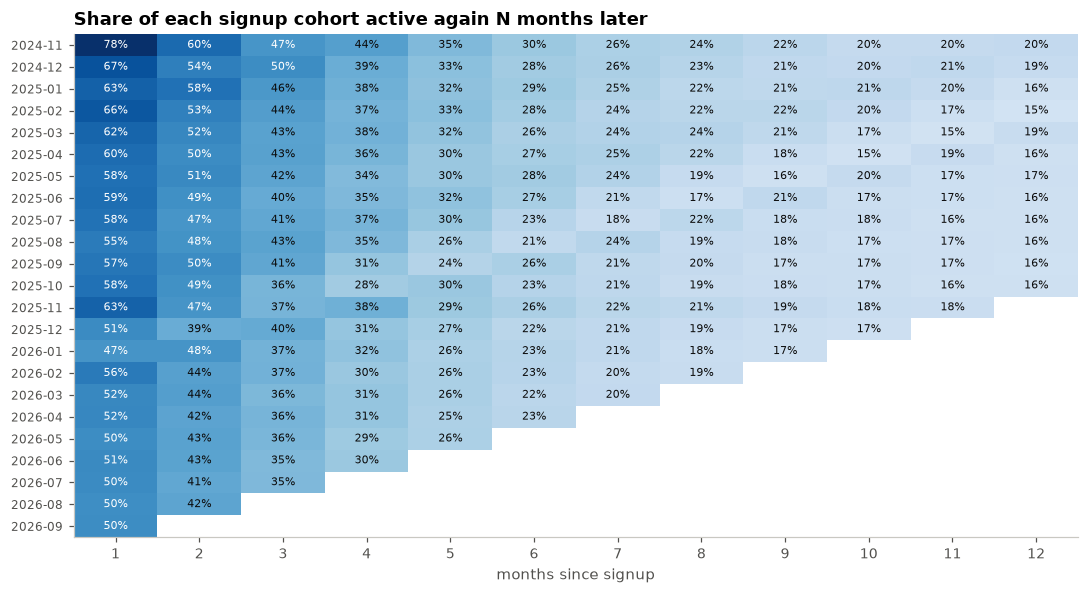

month-1 retention: cohorts Nov 2024–Mar 2025 67.2% vs cohorts from Jun 2025 53.6% (Welch t-test across cohorts p=0.0058)


In [11]:
mi = (DAYS.year - 2024) * 12 + DAYS.month                      # month index per day
su = ((U["signup_date"].dt.year - 2024) * 12 + U["signup_date"].dt.month).values
sm_ = su[S["user_id"].values - 1]
age_m = mi.values[S["day"].values] - sm_
key = np.unique(S["user_id"].values.astype(np.int64) * 64 + age_m)
coh = pd.DataFrame({"cohort": su[key // 64 - 1], "age": key % 64})
coh = coh[(coh["cohort"] >= mi[0]) & (coh["age"] <= 12)]
ret = coh.groupby(["cohort", "age"]).size().unstack()
ret = ret.div(ret[0], axis=0).drop(columns=0)
ret.index = [f"{2024 + (c - 1) // 12}-{(c - 1) % 12 + 1:02d}" for c in ret.index]
ret = ret.iloc[:-1]
ret.to_csv(OUT / "cohort_retention.csv")
fig, ax = plt.subplots(figsize=(10, 5.5))
im = ax.imshow(ret.values, aspect="auto", cmap="Blues", vmin=0, vmax=np.nanmax(ret.values))
ax.set_xticks(range(ret.shape[1])); ax.set_xticklabels(ret.columns); ax.set_yticks(range(len(ret))); ax.set_yticklabels(ret.index, fontsize=8)
ax.set_xlabel("months since signup"); ax.grid(False)
for i in range(ret.shape[0]):
    for j in range(ret.shape[1]):
        v_ = ret.values[i, j]
        if not np.isnan(v_):
            ax.text(j, i, f"{v_:.0%}", ha="center", va="center", fontsize=7, color="white" if v_ > 0.6 * np.nanmax(ret.values) else INK)
ax.set_title("Share of each signup cohort active again N months later")
save(fig, "02_cohort_retention")
m1 = ret[1]
pre, post = m1[m1.index < "2025-04"], m1[(m1.index >= "2025-06")]
print(f"month-1 retention: cohorts Nov 2024–Mar 2025 {pre.mean():.1%} vs cohorts from Jun 2025 {post.mean():.1%} "
      f"(Welch t-test across cohorts p={stats.ttest_ind(pre, post, equal_var=False).pvalue:.4f})")

Newer cohorts come back **less** often than older ones (month-1 retention falls from about two-thirds to just over half).
Traffic growth over the two years is therefore acquisition-led: the user base grows faster than return visits do.
(In this synthetic store that is a property of the generator — return visits are shared across a growing base — but it is
exactly the pattern a real acquisition-heavy growth phase produces, and the cohort view is how it is detected.)

## B5. Loyalty programme: correlation is not the programme's effect
Members convert far better than non-members. But high-intent customers are the ones who join. To separate **selection**
from **effect** we take users who signed up before 2025, and compare their conversion *before the programme existed*
with their conversion after 1 Jul 2025, for those who joined by then vs those who never joined.

In [12]:
jd = ((U["loyalty_join_date"] - START).dt.days).fillna(10 ** 6).astype(int).values
sd_ = ((U["signup_date"] - START).dt.days).values
grp = np.where(jd < day_index("2025-07-01"), "joined", np.where(jd >= 10 ** 6, "never joined", "later"))
old = sd_ < day_index("2025-01-01")
u = S["user_id"].values - 1
sel = old[u] & (grp[u] != "later")
dd_ = S.loc[sel, ["day", "purchased"]].assign(group=grp[u][sel])
dd_["period"] = np.where(dd_["day"] < day_index("2025-04-01"), "before launch", np.where(dd_["day"] >= day_index("2025-07-01"), "after joining", ""))
t = dd_[dd_["period"] != ""].groupby(["group", "period"]).agg(sessions=("purchased", "size"), orders=("purchased", "sum"))
t["conversion"] = t["orders"] / t["sessions"]
display(t)
c = t["conversion"]
naive = c[("joined", "after joining")] / c[("never joined", "after joining")] - 1
pre_gap = c[("joined", "before launch")] / c[("never joined", "before launch")] - 1
lr = np.log(c[("joined", "after joining")] / c[("joined", "before launch")]) - np.log(c[("never joined", "after joining")] / c[("never joined", "before launch")])
se = np.sqrt(((1 - t["conversion"]) / t["orders"]).sum())
print(f"naive comparison after launch (member vs non-member conversion): {naive:+.1%}")
print(f"gap that already existed BEFORE the programme (selection):       {pre_gap:+.1%}")
print(f"difference-in-differences estimate of the programme effect:      {np.exp(lr) - 1:+.1%} "
      f"[95% CI {np.exp(lr - 1.96 * se) - 1:+.1%}, {np.exp(lr + 1.96 * se) - 1:+.1%}]")
pd.DataFrame({"measure": ["naive member vs non-member", "pre-existing gap (selection)", "DiD programme effect", "DiD lo", "DiD hi"],
              "value": [naive, pre_gap, np.exp(lr) - 1, np.exp(lr - 1.96 * se) - 1, np.exp(lr + 1.96 * se) - 1]}).to_csv(OUT / "loyalty_did.csv", index=False)

sessions  orders  conversion
group        period                                     
joined       after joining    500421   36730      0.0734
             before launch    556295   33731      0.0606
never joined after joining   1669398   80464      0.0482
             before launch   2760747  130475      0.0473

naive comparison after launch (member vs non-member conversion): +52.3%
gap that already existed BEFORE the programme (selection):       +28.3%
difference-in-differences estimate of the programme effect:      +18.7% [95% CI +16.7%, +20.7%]


Future members already converted much better than everyone else *before the programme launched*. More than half of the
naive member premium is selection; the difference-in-differences estimate is the defensible number for the programme's
own contribution. (CIs here treat sessions as independent; users contribute several sessions, so the true interval is
somewhat wider — the point estimate is unaffected.)